# Financial Document Analysis Agent

**CSC3173 Artificial Intelligence: Programming Assignment 02**

This notebook builds an agent that answers financial-analysis questions about **Apple Inc.**
using its annual reports (Form 10-K) for fiscal years **2023, 2024 and 2025**.

The design follows the Medical Document (WHO statistics) Agent from class: PDFs are split into
chunks, embedded and indexed with FAISS, and a LangGraph loop lets a planner choose between
`RETRIEVE`, `CALCULATE`, `REPORT` and `FINISH`. The health-specific parts were replaced with
financial ones: a table-aware retrieval tool for the 10-K net sales tables, a Python calculation
tool, and a report generator that writes a PDF with charts and page citations.

Notebook outline:

| Stage | Section |
|---|---|
| 0 | Agentic components (Medical agent vs Financial agent) |
| A | Document processing |
| B | Semantic retrieval |
| C | Financial retrieval tool |
| D | Financial calculation tool |
| E | Report generation tool |
| F | LangGraph agent (state, planner, nodes, routing) |
| G | Test questions Q1 to Q3 and PDF report |

## 0. Agentic Components: Medical Document Agent vs Financial Document Agent

### Components identified in the Medical Document Agent (class demo)

| Component | Medical Document Agent (WHO World Health Statistics 2022 to 2024) |
|---|---|
| **Goal** | Answer a question about a global health indicator (e.g. under-five mortality rate) across the three WHO reports and describe the trend. |
| **State** | `AgentState`: `question`, `indicator_name`, `retrieved_context`, `values_by_year`, `calc_result`, `numbers_found`, `report`, `next_action`, `steps_done`. |
| **Planner** | `planner_node`: Qwen2.5-1.5B is shown which steps are done and whether context, calculation and report exist, and answers RETRIEVE / CALCULATE / REPORT / FINISH. Unrecognised output defaults to FINISH. |
| **Tools** | `health_retrieval_tool` (FAISS search), `retrieve_within_year`, `extract_indicator_value` (Qwen + regex fallback), `calculate_percent_change` (Python), `generate_full_health_report` (Qwen), `extract_cause_breakdown`. |
| **Actions / nodes** | `planner`, `retrieve`, `calculate`, `report`. |
| **Routing / iteration** | `add_conditional_edges` from the planner using `next_action`; every action node has an edge back to the planner, so the graph loops. |
| **Termination** | FINISH maps to `END` once a report exists; `recursion_limit=25` as a safety net. |

### How each component was adapted for the Financial Document Agent

| Component | Financial Document Agent (Apple 10-K FY2023 to FY2025) |
|---|---|
| **Goal** | Answer analyst questions about Apple's revenue (total, by product category and by region) with exact figures, calculations and page citations. |
| **State** | `FinanceAgentState` adds `task`, `table`, `target_years`, `financial_data` (figures per year), `evidence` (file and page), `retrieval_attempts`, `facts`, `analysis`, `chart_path`, `planner_log`, `iteration`. |
| **Planner** | Qwen still proposes the action, but `valid_actions()` checks it against the state and overrides invalid or repeated choices. `MAX_ITERATIONS` forces FINISH. |
| **Tools** | Semantic retrieval (`semantic_search` with fiscal-year filter), financial retrieval tool (`retrieve_financial_table`: search + table parser, Qwen fallback with validation), calculation tool (`financial_calculator`: % change, absolute change, CAGR, contribution share, growth ranking), report tool (`generate_analysis` with number check, `make_chart`, PDF export). |
| **Actions / nodes** | `parse_question` (new: Qwen classifies the task), `planner`, `retrieve`, `calculate`, `report`. |
| **Routing / iteration** | Same conditional routing. RETRIEVE can run again for years that were not found, using a wider search over all filings (later 10-Ks repeat earlier years). |
| **Termination** | FINISH when a report exists, or when the iteration limit is reached; `recursion_limit=40`. |

### Problems seen in the class run and how they were handled here

| Observed in the Medical Agent output | Change in the Financial Agent |
|---|---|
| The regex took the year itself as a value (`'2024': 2024.0`), so the chart showed a value of about 2000. | Values come from table rows, aligned to the column years in the table header. Year-like numbers are rejected by the fallback extractor. |
| The 2023 value (12) was taken from an unrelated sentence. | Each value is tied to a named row of a named table, with the page recorded as evidence. |
| The planner chose RETRIEVE twice. | The rule guard only accepts actions that are valid for the current state. |
| The report invented an "absolute increase of 1931". | Facts are calculated in Python and every number in the LLM text is checked; unsupported text is replaced by a template. |
| `clean_text`, `FPDF` and `XPos`/`YPos` were used in the PDF cell without being defined or imported. | Defined and imported in the PDF export cell. |

## Setup
Mount Google Drive (on Colab) and set the project paths. The three 10-K PDFs go in `Finance_AI_Agent/data/` (or directly in `Finance_AI_Agent/`).

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/Demo/AI/Finance_AI_Agent"
else:
    PROJECT_DIR = os.path.abspath(".")

DATA_DIR = os.path.join(PROJECT_DIR, "data")
if not os.path.isdir(DATA_DIR):
    DATA_DIR = PROJECT_DIR
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project dir:", PROJECT_DIR)
print("Data dir   :", DATA_DIR)
print("Output dir :", OUTPUT_DIR)

Mounted at /content/drive
Project dir: /content/drive/MyDrive/Demo/AI/Finance_AI_Agent
Data dir   : /content/drive/MyDrive/Demo/AI/Finance_AI_Agent/data
Output dir : /content/drive/MyDrive/Demo/AI/Finance_AI_Agent/outputs


### Package installation

In [2]:
%pip install -q pymupdf sentence-transformers faiss-cpu transformers accelerate
%pip install -q langgraph
%pip install -q fpdf2

In [3]:
import fitz  # PyMuPDF
import re, glob, json, warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


## A. Document Processing

Each PDF is opened with PyMuPDF and the text of every page is kept together with its metadata
(source file, page number, fiscal year).

The class notebook took the year from the file name. Here the fiscal year is read from the cover
page of the filing (*"For the fiscal year ended September 27, 2025"*), so renamed files still get
the correct year. Only PDFs whose first page says *FORM 10-K* are loaded, which keeps the
generated report PDF out of the index if it ends up in the same folder.

In [4]:
def is_10k_filing(doc) -> bool:
    return "FORM 10-K" in doc[0].get_text().upper()

def detect_fiscal_year(doc, path: str) -> str:
    cover = doc[0].get_text().replace("\xa0", " ")
    match = re.search(r"fiscal year ended\s+[A-Za-z]+\s+\d{1,2},\s+(20\d{2})", cover, re.IGNORECASE)
    if match:
        return match.group(1)
    match = re.search(r"(20\d{2})", os.path.basename(path))
    return match.group(1) if match else "unknown"

def clean_page_text(text: str) -> str:
    text = text.replace("\xa0", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\s*\n\s*", "\n", text)
    return text.strip()

def extract_pdf_pages(pdf_path: str) -> list[dict]:
    doc = fitz.open(pdf_path)
    if not is_10k_filing(doc):
        return []
    fiscal_year = detect_fiscal_year(doc, pdf_path)
    pages = []
    for i, page in enumerate(doc, start=1):
        text = clean_page_text(page.get_text())
        if text:
            pages.append({"text": text, "page": i, "year": fiscal_year,
                          "source": os.path.basename(pdf_path)})
    return pages

pdf_paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.pdf")))
assert pdf_paths, f"No PDF files found in {DATA_DIR}"

all_pages = []
for path in pdf_paths:
    pages = extract_pdf_pages(path)
    if pages:
        all_pages.extend(pages)
        print(f"{os.path.basename(path):28s} -> FY{pages[0]['year']}, {len(pages)} pages")

AVAILABLE_YEARS = sorted({p["year"] for p in all_pages if p["year"] != "unknown"})
print("Fiscal years available:", AVAILABLE_YEARS)

apple_10k_2023.pdf           -> FY2023, 80 pages
apple_10k_2024.pdf           -> FY2024, 121 pages
apple_10k_2025.pdf           -> FY2025, 80 pages
Fiscal years available: ['2023', '2024', '2025']


In [5]:
# quick lookup of the full text of any page, used later by the table parser
page_lookup = {(p["source"], p["page"]): p for p in all_pages}

summary = (pd.DataFrame(all_pages)
           .assign(words=lambda d: d["text"].str.split().str.len())
           .groupby(["year", "source"])
           .agg(pages=("page", "count"), words=("words", "sum")))
summary

,,pages,words
year,source,,
2023,apple_10k_2023.pdf,80,41522
2024,apple_10k_2024.pdf,121,64170
2025,apple_10k_2025.pdf,80,42050


### Chunking with source / year / page metadata

Pages are split into overlapping word windows. Every chunk keeps the metadata of its page so
answers can always be traced back to a page in a filing.

In [6]:
def chunk_text(text: str, chunk_size: int = 250, overlap: int = 50) -> list[str]:
    words = text.split()
    if len(words) <= chunk_size:
        return [" ".join(words)]
    chunks, start = [], 0
    while start < len(words):
        chunks.append(" ".join(words[start:start + chunk_size]))
        if start + chunk_size >= len(words):
            break
        start += chunk_size - overlap
    return chunks

def build_chunks(pages: list[dict]) -> list[dict]:
    out = []
    for page in pages:
        for piece in chunk_text(page["text"]):
            out.append({"text": piece, "page": page["page"], "year": page["year"],
                        "source": page["source"]})
    return out

chunks = build_chunks(all_pages)
print(f"Total chunks: {len(chunks)}")
print(pd.Series([c["year"] for c in chunks]).value_counts().sort_index().to_string())

Total chunks: 817
2023    230
2024    351
2025    236


## B. Semantic Retrieval

Chunks are embedded with `all-MiniLM-L6-v2` (normalised vectors), so the inner product in a
FAISS `IndexFlatIP` index is the cosine similarity. `semantic_search` can search the whole
collection or only the chunks of one fiscal year, which plays the same role as
`retrieve_within_year` in the class notebook.

In [7]:
from sentence_transformers import SentenceTransformer
import faiss

device = "cuda" if torch.cuda.is_available() else "cpu"
embed_model = SentenceTransformer("all-MiniLM-L6-v2", device=device)

embeddings = embed_model.encode([c["text"] for c in chunks], batch_size=64, show_progress_bar=True,
                                convert_to_numpy=True, normalize_embeddings=True).astype(np.float32)

faiss_index = faiss.IndexFlatIP(embeddings.shape[1])
faiss_index.add(embeddings)

# chunk ids per fiscal year for year-restricted search
year_to_ids = {}
for i, c in enumerate(chunks):
    year_to_ids.setdefault(c["year"], []).append(i)

print(f"FAISS index built: {faiss_index.ntotal} vectors, dim={embeddings.shape[1]}, device={device}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

FAISS index built: 817 vectors, dim=384, device=cuda


In [8]:
def semantic_search(query: str, k: int = 5, year: str | None = None) -> list[dict]:
    q = embed_model.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
    if year is None:
        scores, idxs = faiss_index.search(q, k)
        hits = list(zip(scores[0], idxs[0]))
    else:
        ids = year_to_ids.get(year, [])
        if not ids:
            return []
        scores = embeddings[ids] @ q[0]
        top = np.argsort(-scores)[:k]
        hits = [(scores[j], ids[j]) for j in top]
    return [{**chunks[i], "score": float(s)} for s, i in hits]

for hit in semantic_search("total net sales by product category", k=3, year="2025"):
    print(f"[{hit['source']} FY{hit['year']} p.{hit['page']}] score={hit['score']:.3f}")
    print("   ", hit["text"][:160], "...")

[apple_10k_2025.pdf FY2025 p.42] score=0.505
    Company does not reflect the sale of these components in products net sales. Rather, the Company recognizes any gain on these sales as a reduction of products c ...
[apple_10k_2025.pdf FY2025 p.50] score=0.462
    parties, related cost of sales, and operating expenses directly attributable to the segment. The information provided to the CODM for purposes of making decisio ...
[apple_10k_2025.pdf FY2025 p.39] score=0.439
    The following table shows disaggregated net sales, as well as the portion of total net sales that was previously deferred, for 2025, 2024 and 2023 (in millions) ...


## Qwen loading

Qwen2.5-1.5B-Instruct is the language model of the agent (same as in class). It is used for
understanding the question, for the planner, as a fallback extractor and for writing the
analysis text. It is **not** used for any arithmetic.

In [9]:
from transformers import AutoTokenizer, AutoModelForCausalLM

QWEN_MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
qwen_tokenizer = AutoTokenizer.from_pretrained(QWEN_MODEL_ID)
qwen_model = AutoModelForCausalLM.from_pretrained(
    QWEN_MODEL_ID,
    dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto")
qwen_model.eval()
print("Qwen loaded on", qwen_model.device)

def generate_with_qwen(prompt: str, system_prompt: str = "You are a careful financial analyst.",
                       max_new_tokens: int = 300) -> str:
    messages = [{"role": "system", "content": system_prompt},
                {"role": "user", "content": prompt}]
    text = qwen_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = qwen_tokenizer(text, return_tensors="pt").to(qwen_model.device)
    with torch.no_grad():
        output = qwen_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return qwen_tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen loaded on cuda:0


## C. Financial Retrieval Tool

Financial questions need exact figures, and the 10-K keeps them in tables. In the class notebook,
values were pulled out of free text by the LLM plus a regex, which caused two problems in its output:
the year *2024* was read as the indicator value, and the 2023 value was wrong.

The financial retrieval tool works in two steps:

1. **Semantic search** (restricted to one fiscal year) finds the page with the required table.
2. **Table parser:** on that page the rows of the table are read in order and the numbers are
   matched to the column years from the table header (`2025 Change 2024 Change 2023`).
   Percent-change columns and footnote markers are removed first, so only dollar amounts
   (in millions) are kept.

Two tables are supported: *net sales by category* (iPhone, Mac, iPad, Wearables/Home/Accessories,
Services) and *net sales by reportable segment* (Americas, Europe, Greater China, Japan,
Rest of Asia Pacific). If the parser cannot read a row, Qwen is asked to extract the value from
the retrieved text, and the answer is only accepted if that number really appears in the text.

In [10]:
TABLE_SPECS = {
    "category": {
        "title": "Net sales by category",
        "anchor": "net sales by category",
        "query": "net sales by category iPhone Mac iPad Wearables Home and Accessories Services total net sales",
        "rows": ["iPhone", "Mac", "iPad", "Wearables, Home and Accessories", "Services", "Total net sales"],
    },
    "segment": {
        "title": "Net sales by reportable segment",
        "anchor": "net sales by reportable segment",
        "query": "net sales by reportable segment Americas Europe Greater China Japan Rest of Asia Pacific",
        "rows": ["Americas", "Europe", "Greater China", "Japan", "Rest of Asia Pacific", "Total net sales"],
    },
}

AMOUNT = r"\d{1,3}(?:,\d{3})+"   # amounts in the tables are in millions, e.g. 209,586

def parse_financial_table(page_text: str, spec: dict) -> dict | None:
    text = re.sub(r"\s+", " ", page_text)
    start = text.lower().find(spec["anchor"])
    if start < 0:
        return None
    body = text[start:]
    header = re.search(r"(20\d{2})\s+Change\s+(20\d{2})\s+Change\s+(20\d{2})", body)
    if not header:
        return None
    col_years = list(header.groups())
    body = body[header.end():]
    body = re.sub(r"\(?\d+(?:\.\d+)?\)?\s*%|—\s*%|-\s*%", " ", body)   # drop percent-change columns
    body = re.sub(r"\(\d\)", " ", body)                                      # drop footnote markers

    rows, pos = {}, 0
    for label in spec["rows"]:
        at = body.find(label, pos)
        if at < 0:
            continue
        after = body[at + len(label): at + len(label) + 90]
        amounts = re.findall(AMOUNT, after)[:len(col_years)]
        if len(amounts) == len(col_years):
            rows[label] = {y: float(a.replace(",", "")) for y, a in zip(col_years, amounts)}
            pos = at + len(label)
    return {"columns": col_years, "rows": rows} if rows else None

In [11]:
def llm_extract_value(label: str, context: str, year: str) -> float | None:
    # fallback extractor: Qwen reads the text, Python checks the number really is in the text
    prompt = f'''From the text below, give the value of "{label}" for fiscal year {year},
in millions of US dollars. Reply in exactly this format:
Value: <number>
If the value is not in the text, reply: Value: not found

Text:
{context[:3000]}
'''
    answer = generate_with_qwen(prompt, max_new_tokens=20)
    match = re.search(r"Value:\s*\$?\s*([\d,]+(?:\.\d+)?)", answer)
    if not match:
        return None
    raw = match.group(1)
    value = float(raw.replace(",", ""))
    if 1990 <= value <= 2100 and "," not in raw:   # a year, not an amount
        return None
    if raw not in context and f"{value:,.0f}" not in context:
        return None
    return value

In [12]:
def retrieve_financial_table(table: str, year: str, attempt: int = 1) -> dict | None:
    # Attempt 1: search inside the filing for that fiscal year.
    # Attempt 2: search every filing; later 10-Ks repeat earlier years as comparative columns.
    spec = TABLE_SPECS[table]
    hits = (semantic_search(spec["query"], k=8, year=year) if attempt == 1
            else semantic_search(spec["query"], k=20))
    seen = set()
    for hit in hits:
        key = (hit["source"], hit["page"])
        if key in seen:
            continue
        seen.add(key)
        parsed = parse_financial_table(page_lookup[key]["text"], spec)
        if not parsed or year not in parsed["columns"]:
            continue
        values = {label: cols[year] for label, cols in parsed["rows"].items()}
        missing = [r for r in spec["rows"] if r not in values]
        for label in missing:
            value = llm_extract_value(label, page_lookup[key]["text"], year)
            if value is not None:
                values[label] = value
        return {"table": table, "year": year, "values": values, "source": hit["source"],
                "page": hit["page"], "filing_year": hit["year"], "score": hit["score"],
                "method": "table parser" + (" + LLM fallback" if missing else ""),
                "all_columns": parsed["rows"]}
    return None

def financial_retrieval_tool(query: str, k: int = 4, year: str | None = None) -> str:
    # text retrieval with citations, used as context for the written analysis
    return "\n\n".join(f"[{h['source']} (FY{h['year']}) p.{h['page']}]\n{h['text']}"
                       for h in semantic_search(query, k=k, year=year))

In [13]:
# test: category and segment tables for every fiscal year
for table in TABLE_SPECS:
    for year in AVAILABLE_YEARS:
        r = retrieve_financial_table(table, year)
        print(f"{table:8s} FY{year}: {r['source']} p.{r['page']} ({r['method']})")
        print("   ", {k: f"{v:,.0f}" for k, v in r["values"].items()})

category FY2023: apple_10k_2023.pdf p.25 (table parser)
    {'iPhone': '200,583', 'Mac': '29,357', 'iPad': '28,300', 'Wearables, Home and Accessories': '39,845', 'Services': '85,200', 'Total net sales': '383,285'}
category FY2024: apple_10k_2024.pdf p.26 (table parser)
    {'iPhone': '201,183', 'Mac': '29,984', 'iPad': '26,694', 'Wearables, Home and Accessories': '37,005', 'Services': '96,169', 'Total net sales': '391,035'}
category FY2025: apple_10k_2025.pdf p.26 (table parser)
    {'iPhone': '209,586', 'Mac': '33,708', 'iPad': '28,023', 'Wearables, Home and Accessories': '35,686', 'Services': '109,158', 'Total net sales': '416,161'}
segment  FY2023: apple_10k_2023.pdf p.24 (table parser)
    {'Americas': '162,560', 'Europe': '94,294', 'Greater China': '72,559', 'Japan': '24,257', 'Rest of Asia Pacific': '29,615', 'Total net sales': '383,285'}
segment  FY2024: apple_10k_2024.pdf p.25 (table parser)
    {'Americas': '167,045', 'Europe': '101,328', 'Greater China': '66,952', 'Japan': '2

In [14]:
# consistency check: the same fiscal year appears in up to three filings (as a comparative column)
check_rows = []
for year in AVAILABLE_YEARS:
    for filing in AVAILABLE_YEARS:
        r = retrieve_financial_table("category", filing)
        if r and year in r["all_columns"]["Total net sales"]:
            check_rows.append({"fiscal_year": year, "reported_in": f"FY{filing} 10-K",
                               "total_net_sales_$m": r["all_columns"]["Total net sales"][year]})
pd.DataFrame(check_rows).pivot(index="fiscal_year", columns="reported_in", values="total_net_sales_$m")

reported_in,FY2023 10-K,FY2024 10-K,FY2025 10-K
fiscal_year,,,
2023,383285.0,383285.0,383285.0
2024,NaN,391035.0,391035.0
2025,NaN,NaN,416161.0


In [15]:
# test of the LLM fallback extractor on a retrieved page (only used when the parser misses a row)
sample = retrieve_financial_table("category", AVAILABLE_YEARS[-1])
sample_text = page_lookup[(sample["source"], sample["page"])]["text"]
llm_value = llm_extract_value("iPhone net sales", sample_text, AVAILABLE_YEARS[-1])
print("Qwen fallback, iPhone:", llm_value)
print("Table parser,  iPhone:", sample["values"]["iPhone"])
print("Agree:", llm_value == sample["values"]["iPhone"])

Qwen fallback, iPhone: 209586.0
Table parser,  iPhone: 209586.0
Agree: True


## D. Financial Calculation Tool

All arithmetic is done in Python. The LLM only receives the finished numbers.

* percentage change: `((V_new - V_old) / V_old) x 100`
* absolute change
* compound annual growth rate (CAGR)
* contribution share of each category or region to total net sales
* growth of every line item between two years, with the highest and lowest performer

In [16]:
def percent_change(v_old: float, v_new: float) -> float | None:
    return None if not v_old else (v_new - v_old) / v_old * 100

def absolute_change(v_old: float, v_new: float) -> float:
    return v_new - v_old

def cagr(v_old: float, v_new: float, n_years: int) -> float | None:
    if not v_old or n_years <= 0:
        return None
    return ((v_new / v_old) ** (1 / n_years) - 1) * 100

def contribution_shares(values: dict, total: float) -> dict:
    return {k: v / total * 100 for k, v in values.items()}

def growth_table(old: dict, new: dict) -> dict:
    return {k: {"old": old[k], "new": new[k], "abs_change": absolute_change(old[k], new[k]),
                "pct_change": percent_change(old[k], new[k])}
            for k in old if k in new}

def financial_calculator(operation: str, **kw) -> dict:
    if operation == "total_change":
        series, y_old, y_new = kw["series"], kw["year_old"], kw["year_new"]
        v_old, v_new = series[y_old], series[y_new]
        yoy = {f"{a}->{b}": percent_change(series[a], series[b])
               for a, b in zip(sorted(series), sorted(series)[1:])}
        return {"operation": operation, "year_old": y_old, "year_new": y_new,
                "value_old": v_old, "value_new": v_new,
                "absolute_change": absolute_change(v_old, v_new),
                "percent_change": percent_change(v_old, v_new),
                "cagr": cagr(v_old, v_new, int(y_new) - int(y_old)),
                "year_over_year": yoy, "series": series}

    if operation == "top_contributor":
        items, total = kw["items"], kw["total"]
        shares = contribution_shares(items, total)
        ranking = sorted(items, key=items.get, reverse=True)
        return {"operation": operation, "year": kw["year"], "total": total,
                "items": items, "shares": shares, "ranking": ranking,
                "top": ranking[0], "top_value": items[ranking[0]], "top_share": shares[ranking[0]],
                "sum_check": sum(items.values()) - total}

    if operation == "growth_ranking":
        table = growth_table(kw["old"], kw["new"])
        ranking = sorted(table, key=lambda k: table[k]["pct_change"], reverse=True)
        share_old = contribution_shares(kw["old"], kw["total_old"])
        share_new = contribution_shares(kw["new"], kw["total_new"])
        return {"operation": operation, "year_old": kw["year_old"], "year_new": kw["year_new"],
                "growth": table, "ranking": ranking, "fastest": ranking[0], "slowest": ranking[-1],
                "share_old": share_old, "share_new": share_new,
                "total_pct_change": percent_change(kw["total_old"], kw["total_new"])}

    raise ValueError(f"Unknown operation: {operation}")

In [17]:
# sanity checks on the calculator
assert percent_change(100, 110) == 10
assert absolute_change(383_285, 416_161) == 32_876
assert round(cagr(100, 121, 2), 6) == 10
assert percent_change(0, 5) is None
demo = financial_calculator("top_contributor", year="demo", items={"A": 30, "B": 70}, total=100)
assert demo["top"] == "B" and demo["top_share"] == 70
print("Calculator checks passed.")

Calculator checks passed.


## E. Report Generation Tool

The report has three parts:

1. a short **answer** sentence built directly from the calculated values;
2. an **analysis** paragraph written by Qwen from a list of verified facts and the retrieved
   10-K commentary;
3. a **chart** and the **source pages** used.

In the class notebook output the LLM invented numbers (for example "an absolute increase of 1931
deaths"). To prevent this, every number in Qwen's text is checked against the calculated facts,
including its unit (million, billion or %). If any number does not match a fact, a template
paragraph built from the facts is used instead. The 10-K commentary next to the sales table is
given to Qwen only to explain *why* the figures changed.

In [18]:
def money(v: float) -> str:
    return f"{'-' if v < 0 else ''}${abs(v):,.0f} million"

def billions(v: float) -> str:
    return f"{'-' if v < 0 else ''}${abs(v) / 1000:,.1f} billion"

def build_facts(calc: dict) -> list[str]:
    op = calc["operation"]
    if op == "total_change":
        facts = [f"Total net sales FY{y}: {money(v)} ({billions(v)})" for y, v in calc["series"].items()]
        facts += [f"Absolute change FY{calc['year_old']} to FY{calc['year_new']}: {money(calc['absolute_change'])} "
                  f"({billions(calc['absolute_change'])})",
                  f"Percentage change FY{calc['year_old']} to FY{calc['year_new']}: {calc['percent_change']:.2f}%",
                  f"Compound annual growth rate: {calc['cagr']:.2f}% per year"]
        facts += [f"Year-over-year change FY{k.replace('->', ' to FY')}: {v:.2f}%"
                  for k, v in calc["year_over_year"].items()]
        return facts
    if op == "top_contributor":
        facts = [f"Total net sales FY{calc['year']}: {money(calc['total'])}"]
        facts += [f"{k} net sales FY{calc['year']}: {money(calc['items'][k])}, "
                  f"{calc['shares'][k]:.1f}% of total" for k in calc["ranking"]]
        facts.append(f"Largest contributor: {calc['top']} with {calc['top_share']:.1f}% of total net sales")
        return facts
    if op == "growth_ranking":
        facts = []
        for k in calc["ranking"]:
            g = calc["growth"][k]
            facts.append(f"{k}: FY{calc['year_old']} {money(g['old'])} -> FY{calc['year_new']} {money(g['new'])}, "
                         f"change {money(g['abs_change'])} ({g['pct_change']:.2f}%), "
                         f"share of total {calc['share_old'][k]:.1f}% -> {calc['share_new'][k]:.1f}%")
        facts.append(f"Fastest growth: {calc['fastest']} ({calc['growth'][calc['fastest']]['pct_change']:.2f}%)")
        facts.append(f"Weakest performance: {calc['slowest']} ({calc['growth'][calc['slowest']]['pct_change']:.2f}%)")
        facts.append(f"Total net sales change: {calc['total_pct_change']:.2f}%")
        return facts
    return []

def answer_sentence(calc: dict) -> str:
    op = calc["operation"]
    if op == "total_change":
        direction = "increased" if calc["absolute_change"] >= 0 else "decreased"
        return (f"Apple's total net sales {direction} from {money(calc['value_old'])} in FY{calc['year_old']} "
                f"to {money(calc['value_new'])} in FY{calc['year_new']}, a change of "
                f"{money(calc['absolute_change'])} ({calc['percent_change']:+.2f}%).")
    if op == "top_contributor":
        return (f"In FY{calc['year']}, {calc['top']} contributed the most revenue with "
                f"{money(calc['top_value'])}, which is {calc['top_share']:.1f}% of total net sales "
                f"({money(calc['total'])}).")
    if op == "growth_ranking":
        f, s = calc["fastest"], calc["slowest"]
        return (f"Between FY{calc['year_old']} and FY{calc['year_new']}, {f} grew the fastest "
                f"({calc['growth'][f]['pct_change']:+.2f}%), while {s} performed the weakest "
                f"({calc['growth'][s]['pct_change']:+.2f}%).")
    return calc.get("note", "Not enough data was found to answer the question.")

In [19]:
NUMBER_WITH_UNIT = re.compile(r"(\d[\d,]*(?:\.\d+)?)\s*(%|percent|million|billion)?", re.IGNORECASE)

def _numbers(text: str) -> list[tuple[float, str]]:
    out = []
    for num, unit in NUMBER_WITH_UNIT.findall(text):
        unit = (unit or "").lower().replace("percent", "%")
        out.append((float(num.replace(",", "")), unit))
    return out

def _close(n: float, a: float) -> bool:
    if abs(n - a) <= 0.051 or (a and abs(n - a) / abs(a) < 0.0005):
        return True
    return n == int(n) and a != int(a) and abs(n - a) < 0.5      # 50.4% written as 50%

def unsupported_numbers(text: str, facts_text: str) -> list[str]:
    # every number in the LLM text must match a fact with the same unit (million / billion / %)
    allowed = _numbers(facts_text)
    bad = []
    for n, unit in _numbers(text):
        if not unit and (n <= 10 or 2000 <= n <= 2100):   # small counts or years
            continue
        if any(u == unit and _close(n, a) for a, u in allowed):
            continue
        bad.append(f"{n:g} {unit}".strip())
    return bad

def template_analysis(calc: dict) -> str:
    # plain-language paragraph built only from calculated values (used when the LLM text fails the check)
    op = calc["operation"]
    if op == "total_change":
        yoy = "; ".join(f"FY{k.replace('->', ' to FY')}: {v:+.2f}%" for k, v in calc["year_over_year"].items())
        return (f"Total net sales went from {money(calc['value_old'])} in FY{calc['year_old']} to "
                f"{money(calc['value_new'])} in FY{calc['year_new']}, an absolute change of "
                f"{money(calc['absolute_change'])} or {calc['percent_change']:+.2f}%. "
                f"Year over year the changes were {yoy}, which corresponds to a compound annual growth "
                f"rate of {calc['cagr']:.2f}% over the period.")
    if op == "top_contributor":
        r = calc["ranking"]
        others = ", ".join(f"{k} ({calc['shares'][k]:.1f}%)" for k in r[1:])
        return (f"{calc['top']} was the largest source of revenue in FY{calc['year']} with "
                f"{money(calc['top_value'])}, or {calc['top_share']:.1f}% of total net sales of "
                f"{money(calc['total'])}. It was followed by {others}.")
    if op == "growth_ranking":
        g = calc["growth"]
        parts = ", ".join(f"{k} {g[k]['pct_change']:+.2f}% ({money(g[k]['old'])} to {money(g[k]['new'])})"
                          for k in calc["ranking"])
        f, s = calc["fastest"], calc["slowest"]
        return (f"From FY{calc['year_old']} to FY{calc['year_new']} the changes in net sales were: {parts}. "
                f"{f} grew the fastest and its share of total net sales moved from "
                f"{calc['share_old'][f]:.1f}% to {calc['share_new'][f]:.1f}%, while {s} had the weakest result "
                f"with its share moving from {calc['share_old'][s]:.1f}% to {calc['share_new'][s]:.1f}%. "
                f"Total net sales changed by {calc['total_pct_change']:+.2f}% over the same period.")
    return calc.get("note", "")

def generate_analysis(question: str, calc: dict, context: str) -> dict:
    facts = build_facts(calc)
    facts_text = "\n".join(f"- {f}" for f in facts)
    prompt = f'''Answer the analyst question using ONLY the verified facts below.
Write one paragraph of 4 to 6 sentences in plain text (no markdown, no bullet points).
Do not calculate new numbers; copy numbers exactly as they appear in the facts.
Use the 10-K excerpts only to explain the reasons behind the numbers (do not copy other numbers from them).

Question: {question}

Verified facts (from Apple 10-K filings, calculated in Python):
{facts_text}

10-K excerpts:
{context[:2500]}
'''
    text = generate_with_qwen(prompt, max_new_tokens=280)
    text = re.sub(r"[*#`]", "", text).strip()
    bad = unsupported_numbers(text, facts_text + "\n" + question)
    if bad:
        return {"text": template_analysis(calc), "llm_text": text, "verified": False, "unsupported": bad}
    return {"text": text, "llm_text": text, "verified": True, "unsupported": []}

In [20]:
def make_chart(calc: dict, path: str) -> str | None:
    op = calc.get("operation")
    fig, ax = plt.subplots(figsize=(7, 4))
    if op == "total_change":
        years = sorted(calc["series"])
        vals = [calc["series"][y] / 1000 for y in years]
        bars = ax.bar([f"FY{y}" for y in years], vals, color="#3b6ea5")
        ax.bar_label(bars, labels=[f"${v:,.1f}B" for v in vals], padding=3)
        ax.set_ylabel("Total net sales (US$ billions)")
        ax.set_ylim(0, max(vals) * 1.15)
        ax.set_title(f"Apple total net sales, FY{years[0]} to FY{years[-1]}")
    elif op == "top_contributor":
        labels = calc["ranking"]
        vals = [calc["items"][k] / 1000 for k in labels]
        colors = ["#3b6ea5" if k == calc["top"] else "#a9bcd0" for k in labels]
        bars = ax.barh(labels[::-1], vals[::-1], color=colors[::-1])
        ax.bar_label(bars, labels=[f"${calc['items'][k]/1000:,.1f}B ({calc['shares'][k]:.1f}%)" for k in labels[::-1]],
                     padding=3)
        ax.set_xlabel("Net sales (US$ billions)")
        ax.set_xlim(0, max(vals) * 1.35)
        ax.set_title(f"Net sales by category, FY{calc['year']}")
    elif op == "growth_ranking":
        labels = calc["ranking"]
        vals = [calc["growth"][k]["pct_change"] for k in labels]
        colors = ["#2e7d32" if v >= 0 else "#c62828" for v in vals]
        bars = ax.barh(labels[::-1], vals[::-1], color=colors[::-1])
        ax.bar_label(bars, labels=[f"{v:+.1f}%" for v in vals[::-1]], padding=3)
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_xlabel("Change in net sales (%)")
        lo, hi = min(vals + [0]), max(vals + [0])
        ax.set_xlim(lo - 6, hi + 6)
        ax.set_title(f"Net sales growth, FY{calc['year_old']} to FY{calc['year_new']}")
    else:
        plt.close(fig)
        return None
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)
    return path

## F. LangGraph Agent

### Agent state

Compared with the class `AgentState`, the state now records *what kind* of question was asked
(`task`, `table`, `target_years`), the figures found per fiscal year, the evidence (file and page)
for each figure, how many retrieval attempts were made per year, and a log of the planner's
decisions.

In [21]:
from typing import TypedDict, List, Dict

class FinanceAgentState(TypedDict):
    question: str
    task: str                         # total_change | top_contributor | growth_ranking
    table: str                        # category | segment
    target_years: List[str]
    financial_data: Dict[str, Dict]   # fiscal year -> {line item: value in $m}
    evidence: List[Dict]
    retrieval_attempts: Dict[str, int]
    context: str
    calc_result: Dict
    facts: List[str]
    analysis: Dict
    chart_path: str
    report: str
    next_action: str
    steps_done: List[str]
    planner_log: List[str]
    iteration: int

MAX_ITERATIONS = 10
MAX_RETRIEVAL_ATTEMPTS = 2
TASKS = ["total_change", "top_contributor", "growth_ranking"]

### Question understanding

Before the planner runs, Qwen classifies the question into one of the analysis tasks. Python
reads the years from the question; *"latest year"* is mapped to the most recent fiscal year that
was loaded. A keyword check guards the label: if Qwen's answer is not an allowed label, or it
contradicts a clear keyword in the question (e.g. *"contributed the most"*), the keyword rule is
used and the decision is written to the log.

In [22]:
def rule_based_task(question: str) -> tuple[str, bool]:
    # returns (task, confident); confident means a clear keyword was found
    q = question.lower()
    if re.search(r"fastest|grew the most|highest growth|growing|growth rate|slowest|best|worst", q):
        return "growth_ranking", True
    if re.search(r"contribut|largest|most revenue|biggest|share of", q):
        return "top_contributor", True
    if re.search(r"total (revenue|net sales)", q) and re.search(r"chang|grow|increas|decreas|trend", q):
        return "total_change", True
    return "total_change", False

def detect_table(question: str) -> str:
    q = question.lower()
    regions = r"region|segment|geograph|americas|europe|china|japan|asia"
    return "segment" if re.search(regions, q) else "category"

def parse_question_node(state: FinanceAgentState) -> FinanceAgentState:
    question = state["question"]
    prompt = f'''Classify the financial question into exactly one label.
TOTAL_CHANGE - how total revenue / net sales changed between years
TOP_CONTRIBUTOR - which product category or region contributed the most revenue in a year
GROWTH_RANKING - which product category or region grew the fastest / performed best or worst between years

Examples:
"How did total net sales change from 2023 to 2024?" -> TOTAL_CHANGE
"Which region had the largest share of revenue in 2024?" -> TOP_CONTRIBUTOR
"Which product category grew the fastest between 2023 and 2025?" -> GROWTH_RANKING

Question: {question}
Reply with only the label.'''
    reply = generate_with_qwen(prompt, max_new_tokens=8).upper()
    llm_task = next((t for t in TASKS if t.upper() in reply.replace(" ", "_")), None)
    rule_task, confident = rule_based_task(question)
    if llm_task and (llm_task == rule_task or not confident):
        task, note = llm_task, "Qwen label used"
    else:
        task, note = rule_task, "keyword rule used"
    state["planner_log"].append(f"parse: Qwen -> {llm_task}, rules -> {rule_task} ({note})")
    state["task"] = task
    state["table"] = detect_table(question)

    years = sorted(set(re.findall(r"\b(20\d{2})\b", question)))
    latest = AVAILABLE_YEARS[-1]
    if state["task"] == "top_contributor":
        state["target_years"] = [years[-1]] if years and "latest" not in question.lower() else [latest]
    else:
        y_old = years[0] if years else AVAILABLE_YEARS[0]
        y_new = years[-1] if len(years) > 1 else latest
        if state["task"] == "total_change":
            state["target_years"] = [str(y) for y in range(int(y_old), int(y_new) + 1)]
        else:
            state["target_years"] = [y_old, y_new]
    state["steps_done"].append("PARSE")
    return state

### Planner node with rule guard

Qwen proposes the next action from a summary of the state (same idea as the class planner).
`valid_actions` then checks the proposal against the state. If Qwen picks an action that is not
valid at that point (for example `RETRIEVE` again when all years are already loaded, which
happened in the class run), the guard replaces it with the expected action and logs the override.
`MAX_ITERATIONS` stops the loop if something goes wrong.

In [23]:
def missing_years(state: FinanceAgentState) -> list[str]:
    return [y for y in state["target_years"] if y not in state["financial_data"]]

def valid_actions(state: FinanceAgentState) -> list[str]:
    if state.get("report"):
        return ["FINISH"]
    retryable = [y for y in missing_years(state)
                 if state["retrieval_attempts"].get(y, 0) < MAX_RETRIEVAL_ATTEMPTS]
    if retryable:
        return ["RETRIEVE"]
    if not state.get("calc_result"):
        return ["CALCULATE"]
    return ["REPORT"]

def planner_node(state: FinanceAgentState) -> FinanceAgentState:
    state["iteration"] = state.get("iteration", 0) + 1
    if state["iteration"] > MAX_ITERATIONS:
        state["next_action"] = "FINISH"
        state["planner_log"].append(f"iter {state['iteration']}: iteration limit reached -> FINISH")
        return state

    missing = missing_years(state)
    prompt = f'''You are the planner of a financial document analysis agent. Decide the single next step.

Question: {state['question']}
Fiscal years needed: {state['target_years']}
Years with figures retrieved: {sorted(state['financial_data']) or 'none'}
Years still missing: {missing or 'none'}
Has calculation result: {'yes' if state.get('calc_result') else 'no'}
Has final report: {'yes' if state.get('report') else 'no'}

Rules:
- If any needed year is still missing, choose RETRIEVE.
- If all years are retrieved but there is no calculation, choose CALCULATE.
- If a calculation exists but no report, choose REPORT.
- If a report exists, choose FINISH.

Reply with exactly one word: RETRIEVE, CALCULATE, REPORT, or FINISH.'''
    reply = generate_with_qwen(prompt, max_new_tokens=6).strip().upper()
    proposed = next((a for a in ["RETRIEVE", "CALCULATE", "REPORT", "FINISH"] if a in reply), "NONE")

    allowed = valid_actions(state)
    if proposed in allowed:
        state["next_action"] = proposed
        note = "accepted"
    else:
        state["next_action"] = allowed[0]
        note = f"overridden by guard (valid: {allowed})"
    state["planner_log"].append(f"iter {state['iteration']}: Qwen -> {proposed}, {note} -> {state['next_action']}")
    return state

### Action nodes

* **retrieve**: calls the financial retrieval tool for every missing fiscal year. A year that is not
  found on the first attempt is tried again on the next iteration with a wider search over all
  filings.
* **calculate**: calls the Python calculation tool for the task.
* **report**: writes the answer, the checked analysis paragraph and the chart.

In [24]:
def commentary_context(state: FinanceAgentState) -> str:
    # the MD&A text right after a sales table explains the changes, so that page and the next one
    # are used as context for the analysis, plus one excerpt from a semantic search on the question
    latest = max(state["target_years"])
    parts = []
    for e in state["evidence"]:
        if e["year"] != latest:
            continue
        for page_no in (e["page"], e["page"] + 1):
            page = page_lookup.get((e["source"], page_no))
            if not page:
                continue
            text = re.sub(r"\s+", " ", page["text"])
            if page_no == e["page"] and "Total net sales" in text:
                text = text[text.find("Total net sales"):]
            parts.append(f"[{e['source']} p.{page_no}] {text}")
    if latest in AVAILABLE_YEARS:
        parts.append(financial_retrieval_tool(state["question"], k=1, year=latest))
    return "\n\n".join(parts)

def retrieve_node(state: FinanceAgentState) -> FinanceAgentState:
    for year in missing_years(state):
        attempt = state["retrieval_attempts"].get(year, 0) + 1
        state["retrieval_attempts"][year] = attempt
        result = retrieve_financial_table(state["table"], year, attempt=attempt)
        if result is None:
            state["planner_log"].append(f"retrieve: FY{year} not found (attempt {attempt})")
            continue
        state["financial_data"][year] = result["values"]
        state["evidence"].append({"year": year, "table": TABLE_SPECS[state["table"]]["title"],
                                  "source": result["source"], "page": result["page"],
                                  "method": result["method"]})
    state["context"] = commentary_context(state)
    state["steps_done"].append("RETRIEVE")
    return state

def calculate_node(state: FinanceAgentState) -> FinanceAgentState:
    data, years, task = state["financial_data"], sorted(state["financial_data"]), state["task"]
    try:
        if task == "total_change" and len(years) >= 2:
            series = {y: data[y]["Total net sales"] for y in years}
            calc = financial_calculator("total_change", series=series, year_old=years[0], year_new=years[-1])
        elif task == "top_contributor" and years:
            y = years[-1]
            items = {k: v for k, v in data[y].items() if k != "Total net sales"}
            calc = financial_calculator("top_contributor", year=y, items=items, total=data[y]["Total net sales"])
        elif task == "growth_ranking" and len(years) >= 2:
            y_old, y_new = years[0], years[-1]
            old = {k: v for k, v in data[y_old].items() if k != "Total net sales"}
            new = {k: v for k, v in data[y_new].items() if k != "Total net sales"}
            calc = financial_calculator("growth_ranking", year_old=y_old, year_new=y_new, old=old, new=new,
                                        total_old=data[y_old]["Total net sales"],
                                        total_new=data[y_new]["Total net sales"])
        else:
            calc = {"operation": "none", "note": f"Not enough data retrieved for years {state['target_years']}."}
    except KeyError as err:
        calc = {"operation": "none", "note": f"Missing line item {err} in the retrieved table."}
    state["calc_result"] = calc
    state["facts"] = build_facts(calc)
    state["steps_done"].append("CALCULATE")
    return state

def report_node(state: FinanceAgentState) -> FinanceAgentState:
    calc = state["calc_result"]
    if calc.get("operation") == "none":
        state["analysis"] = {"text": calc["note"], "verified": True, "unsupported": []}
    else:
        state["analysis"] = generate_analysis(state["question"], calc, state["context"])
    slug = re.sub(r"[^a-z0-9]+", "_", state["question"].lower())[:40].strip("_")
    state["chart_path"] = make_chart(calc, os.path.join(OUTPUT_DIR, f"chart_{slug}.png")) or ""
    state["report"] = answer_sentence(calc) + "\n\n" + state["analysis"]["text"]
    state["steps_done"].append("REPORT")
    return state

### Routing and graph assembly

`parse_question` is the entry node. The planner routes conditionally to one of the action nodes,
and every action node returns to the planner (iteration). `FINISH` maps to `END` (termination).

In [25]:
from langgraph.graph import StateGraph, END

def route_from_planner(state: FinanceAgentState) -> str:
    return {"RETRIEVE": "retrieve", "CALCULATE": "calculate", "REPORT": "report"}.get(state["next_action"], END)

graph = StateGraph(FinanceAgentState)
graph.add_node("parse_question", parse_question_node)
graph.add_node("planner", planner_node)
graph.add_node("retrieve", retrieve_node)
graph.add_node("calculate", calculate_node)
graph.add_node("report", report_node)

graph.set_entry_point("parse_question")
graph.add_edge("parse_question", "planner")
graph.add_conditional_edges("planner", route_from_planner,
                            {"retrieve": "retrieve", "calculate": "calculate", "report": "report", END: END})
for node in ["retrieve", "calculate", "report"]:
    graph.add_edge(node, "planner")

agent = graph.compile()
print("Graph compiled.")
try:
    print(agent.get_graph().draw_ascii())
except Exception:
    pass

Graph compiled.


In [26]:
def new_state(question: str) -> FinanceAgentState:
    return {"question": question, "task": "", "table": "", "target_years": [], "financial_data": {},
            "evidence": [], "retrieval_attempts": {}, "context": "", "calc_result": {}, "facts": [],
            "analysis": {}, "chart_path": "", "report": "", "next_action": "", "steps_done": [],
            "planner_log": [], "iteration": 0}

def run_agent(question: str, verbose: bool = True) -> FinanceAgentState:
    final = agent.invoke(new_state(question), config={"recursion_limit": 40})
    if verbose:
        print("QUESTION:", question)
        print(f"Task: {final['task']} | table: {final['table']} | years: {final['target_years']}")
        print("Steps:", " -> ".join(final["steps_done"] + ["FINISH"]))
        print("\nPlanner log:")
        for line in final["planner_log"]:
            print("  ", line)
        print("\nEvidence:")
        for e in final["evidence"]:
            print(f"   FY{e['year']}: {e['table']} - {e['source']} p.{e['page']} ({e['method']})")
        print("\nFacts:")
        for f in final["facts"]:
            print("   -", f)
        print("\nAnalysis checked against facts:", final["analysis"].get("verified"),
              final["analysis"].get("unsupported") or "")
        print("\n=== REPORT ===\n" + final["report"])
    return final

## G. Test questions

Q1 and Q2 are the questions from the assignment. Q3 is my own question. It needs the regional
(reportable segment) table from two different filings, so it cannot be answered from general
knowledge.

In [27]:
QUESTIONS = {
    "Q1": "How did the company's total revenue change between 2023 and 2025?",
    "Q2": "Which product category contributed the most revenue in the latest year?",
    "Q3": "Which geographic segment grew the fastest between 2023 and 2025, and how did each region's net sales change?",
}
results = {}

In [28]:
results["Q1"] = run_agent(QUESTIONS["Q1"])

QUESTION: How did the company's total revenue change between 2023 and 2025?
Task: total_change | table: category | years: ['2023', '2024', '2025']
Steps: PARSE -> RETRIEVE -> CALCULATE -> REPORT -> FINISH

Planner log:
   parse: Qwen -> total_change, rules -> total_change (Qwen label used)
   iter 1: Qwen -> RETRIEVE, accepted -> RETRIEVE
   iter 2: Qwen -> RETRIEVE, overridden by guard (valid: ['CALCULATE']) -> CALCULATE
   iter 3: Qwen -> CALCULATE, overridden by guard (valid: ['REPORT']) -> REPORT
   iter 4: Qwen -> CALCULATE, overridden by guard (valid: ['FINISH']) -> FINISH

Evidence:
   FY2023: Net sales by category - apple_10k_2023.pdf p.25 (table parser)
   FY2024: Net sales by category - apple_10k_2024.pdf p.26 (table parser)
   FY2025: Net sales by category - apple_10k_2025.pdf p.26 (table parser)

Facts:
   - Total net sales FY2023: $383,285 million ($383.3 billion)
   - Total net sales FY2024: $391,035 million ($391.0 billion)
   - Total net sales FY2025: $416,161 million (

In [29]:
results["Q2"] = run_agent(QUESTIONS["Q2"])

QUESTION: Which product category contributed the most revenue in the latest year?
Task: top_contributor | table: category | years: ['2025']
Steps: PARSE -> RETRIEVE -> CALCULATE -> REPORT -> FINISH

Planner log:
   parse: Qwen -> top_contributor, rules -> top_contributor (Qwen label used)
   iter 1: Qwen -> RETRIEVE, accepted -> RETRIEVE
   iter 2: Qwen -> RETRIEVE, overridden by guard (valid: ['CALCULATE']) -> CALCULATE
   iter 3: Qwen -> CALCULATE, overridden by guard (valid: ['REPORT']) -> REPORT
   iter 4: Qwen -> CALCULATE, overridden by guard (valid: ['FINISH']) -> FINISH

Evidence:
   FY2025: Net sales by category - apple_10k_2025.pdf p.26 (table parser)

Facts:
   - Total net sales FY2025: $416,161 million
   - iPhone net sales FY2025: $209,586 million, 50.4% of total
   - Services net sales FY2025: $109,158 million, 26.2% of total
   - Wearables, Home and Accessories net sales FY2025: $35,686 million, 8.6% of total
   - Mac net sales FY2025: $33,708 million, 8.1% of total
   -

In [30]:
results["Q3"] = run_agent(QUESTIONS["Q3"])

QUESTION: Which geographic segment grew the fastest between 2023 and 2025, and how did each region's net sales change?
Task: growth_ranking | table: segment | years: ['2023', '2025']
Steps: PARSE -> RETRIEVE -> CALCULATE -> REPORT -> FINISH

Planner log:
   parse: Qwen -> total_change, rules -> growth_ranking (keyword rule used)
   iter 1: Qwen -> RETRIEVE, accepted -> RETRIEVE
   iter 2: Qwen -> RETRIEVE, overridden by guard (valid: ['CALCULATE']) -> CALCULATE
   iter 3: Qwen -> CALCULATE, overridden by guard (valid: ['REPORT']) -> REPORT
   iter 4: Qwen -> CALCULATE, overridden by guard (valid: ['FINISH']) -> FINISH

Evidence:
   FY2023: Net sales by reportable segment - apple_10k_2023.pdf p.24 (table parser)
   FY2025: Net sales by reportable segment - apple_10k_2025.pdf p.25 (table parser)

Facts:
   - Japan: FY2023 $24,257 million -> FY2025 $28,703 million, change $4,446 million (18.33%), share of total 6.3% -> 6.9%
   - Europe: FY2023 $94,294 million -> FY2025 $111,032 million, c

Q1


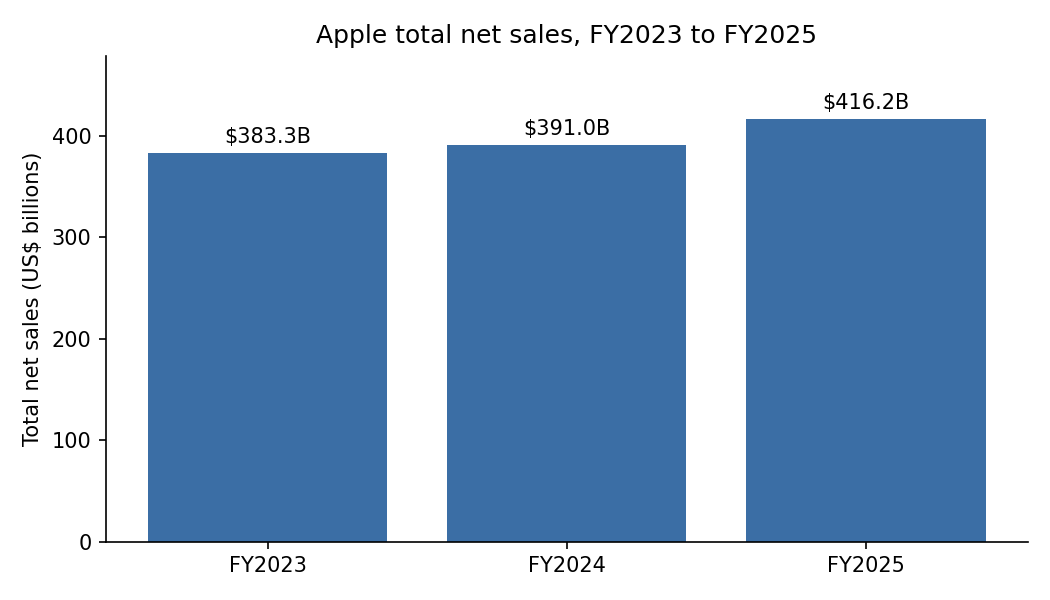

Q2


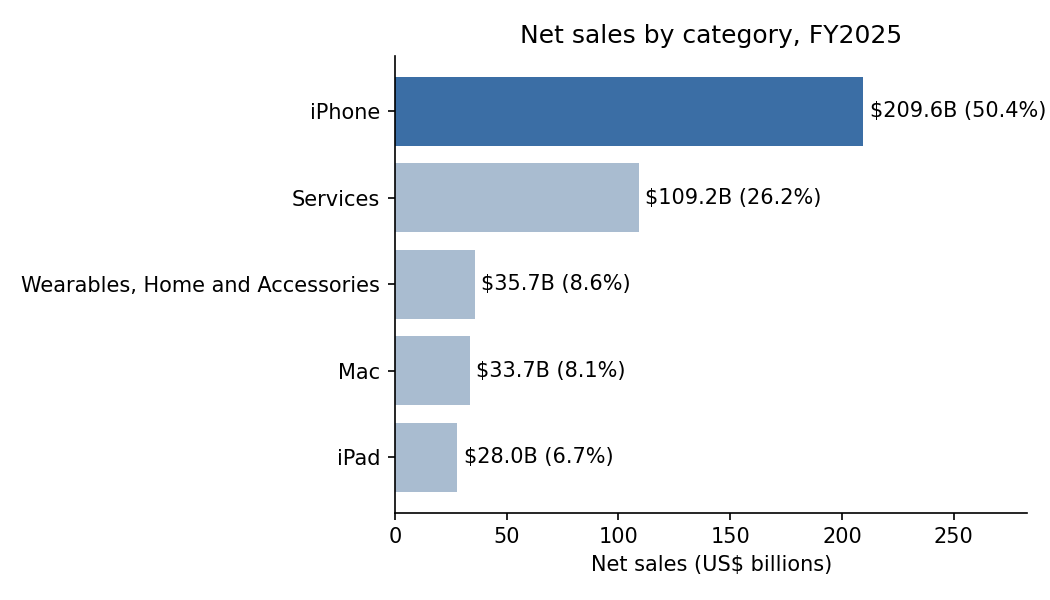

Q3


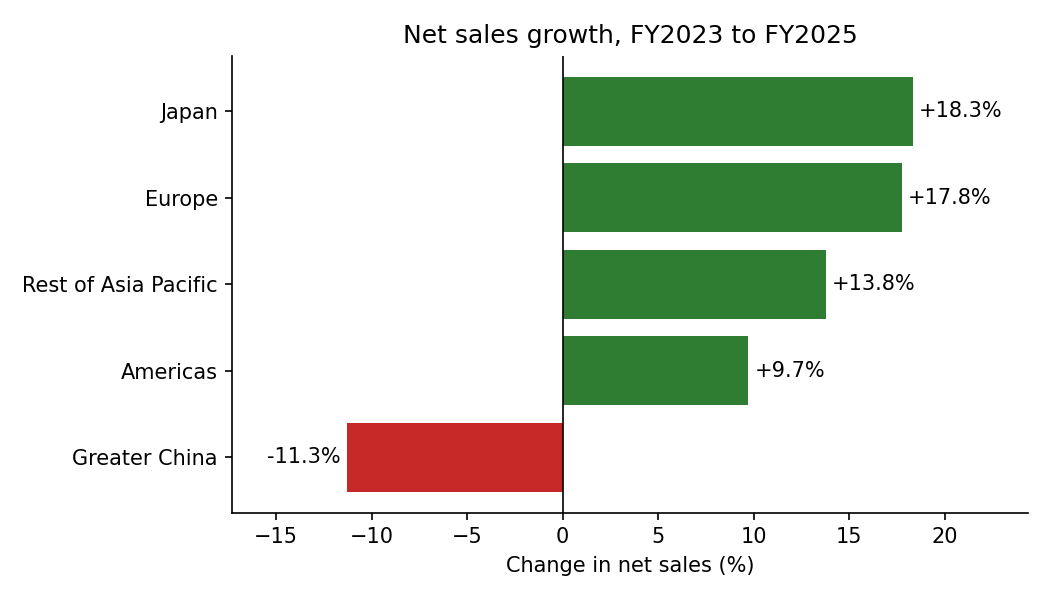

In [31]:
from IPython.display import Image, display
for qid, res in results.items():
    if res["chart_path"]:
        print(qid)
        display(Image(res["chart_path"], width=520))

### Export the output report as PDF

One PDF with a section per question: the question, the answer, the analysis, a table of the
figures used, the chart, the agent trace (planner decisions) and the 10-K pages used as evidence.

In [32]:
from fpdf import FPDF
from fpdf.enums import XPos, YPos

REPLACEMENTS = {"—": "-", "–": "-", "’": "'", "‘": "'", "“": '"', "”": '"',
                "→": "->", "•": "-", "\xa0": " "}

def clean_text(text: str) -> str:
    for a, b in REPLACEMENTS.items():
        text = text.replace(a, b)
    return text.encode("latin-1", "replace").decode("latin-1")

def figures_table(calc: dict) -> tuple[list[str], list[list[str]]]:
    op = calc.get("operation")
    if op == "total_change":
        return ["Fiscal year", "Total net sales ($m)", "YoY change"], [
            [f"FY{y}", f"{v:,.0f}", "" if i == 0 else f"{list(calc['year_over_year'].values())[i-1]:+.2f}%"]
            for i, (y, v) in enumerate(sorted(calc["series"].items()))]
    if op == "top_contributor":
        return ["Category", f"FY{calc['year']} net sales ($m)", "Share of total"], [
            [k, f"{calc['items'][k]:,.0f}", f"{calc['shares'][k]:.1f}%"] for k in calc["ranking"]] + [
            ["Total net sales", f"{calc['total']:,.0f}", "100.0%"]]
    if op == "growth_ranking":
        g = calc["growth"]
        return ["Segment", f"FY{calc['year_old']} ($m)", f"FY{calc['year_new']} ($m)", "Change ($m)", "Change %"], [
            [k, f"{g[k]['old']:,.0f}", f"{g[k]['new']:,.0f}", f"{g[k]['abs_change']:+,.0f}", f"{g[k]['pct_change']:+.2f}%"]
            for k in calc["ranking"]]
    return [], []

def heading(pdf, text, size=12):
    pdf.set_font("Helvetica", "B", size)
    pdf.cell(0, 8, clean_text(text), new_x=XPos.LMARGIN, new_y=YPos.NEXT)

def paragraph(pdf, text, size=10, style=""):
    pdf.set_font("Helvetica", style, size)
    pdf.multi_cell(0, 5, clean_text(text), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.ln(2)

def build_financial_report_pdf(results: dict, questions: dict, out_path: str) -> str:
    pdf = FPDF()
    pdf.set_auto_page_break(auto=True, margin=15)
    pdf.add_page()
    heading(pdf, "Financial Document Analysis Agent - Output Report", 16)
    paragraph(pdf, "Knowledge source: Apple Inc. Form 10-K filings for fiscal years "
                   + ", ".join(AVAILABLE_YEARS) + ". All amounts are in US$ millions unless stated. "
                   "Figures are read from the 10-K tables and all calculations are done in Python; "
                   f"the analysis text is written by {QWEN_MODEL_ID} and checked against the figures.", 9)

    for qid, res in results.items():
        calc = res["calc_result"]
        if pdf.get_y() > 200:
            pdf.add_page()
        heading(pdf, f"{qid}. {questions[qid]}", 12)
        heading(pdf, "Answer", 10)
        paragraph(pdf, answer_sentence(calc), 10, "B")
        heading(pdf, "Analysis", 10)
        paragraph(pdf, res["analysis"]["text"], 10)
        if not res["analysis"].get("verified", True):
            paragraph(pdf, "Note: the model's paragraph contained figures that did not match the calculated "
                           f"facts ({', '.join(res['analysis']['unsupported'])}), so this paragraph was "
                           "written from the facts instead.", 8, "I")

        cols, rows = figures_table(calc)
        if rows:
            heading(pdf, "Figures used", 10)
            pdf.set_font("Helvetica", "", 9)
            with pdf.table(text_align="LEFT", line_height=6) as table:
                r = table.row()
                for c in cols:
                    r.cell(clean_text(c))
                for row in rows:
                    r = table.row()
                    for c in row:
                        r.cell(clean_text(c))
            pdf.ln(3)

        if res["chart_path"] and os.path.exists(res["chart_path"]):
            if pdf.get_y() > 190:
                pdf.add_page()
            pdf.image(res["chart_path"], w=140)
            pdf.ln(2)

        heading(pdf, "Agent trace", 10)
        paragraph(pdf, f"Task: {res['task']} | Table: {TABLE_SPECS[res['table']]['title']} | "
                       f"Years: {', '.join(res['target_years'])}", 9)
        paragraph(pdf, "Steps: " + " -> ".join(res["steps_done"] + ["FINISH"]), 9)
        paragraph(pdf, "\n".join(res["planner_log"]), 8)

        heading(pdf, "Evidence (10-K pages)", 10)
        paragraph(pdf, "\n".join(f"FY{e['year']}: {e['table']} - {e['source']}, page {e['page']} ({e['method']})"
                                 for e in res["evidence"]), 9)
        pdf.ln(4)

    pdf.output(out_path)
    return out_path

report_path = build_financial_report_pdf(results, QUESTIONS, os.path.join(OUTPUT_DIR, "financial_analysis_report.pdf"))
print("Saved", report_path)

Saved /content/drive/MyDrive/Demo/AI/Finance_AI_Agent/outputs/financial_analysis_report.pdf


### Try another question

The agent is not limited to the three test questions. Any question about total net sales,
category or regional contribution, or category/regional growth across the loaded fiscal years
can be asked.

In [33]:
extra = run_agent("Which product category grew the fastest between 2023 and 2025?")

QUESTION: Which product category grew the fastest between 2023 and 2025?
Task: growth_ranking | table: category | years: ['2023', '2025']
Steps: PARSE -> RETRIEVE -> CALCULATE -> REPORT -> FINISH

Planner log:
   parse: Qwen -> growth_ranking, rules -> growth_ranking (Qwen label used)
   iter 1: Qwen -> RETRIEVE, accepted -> RETRIEVE
   iter 2: Qwen -> RETRIEVE, overridden by guard (valid: ['CALCULATE']) -> CALCULATE
   iter 3: Qwen -> CALCULATE, overridden by guard (valid: ['REPORT']) -> REPORT
   iter 4: Qwen -> CALCULATE, overridden by guard (valid: ['FINISH']) -> FINISH

Evidence:
   FY2023: Net sales by category - apple_10k_2023.pdf p.25 (table parser)
   FY2025: Net sales by category - apple_10k_2025.pdf p.26 (table parser)

Facts:
   - Services: FY2023 $85,200 million -> FY2025 $109,158 million, change $23,958 million (28.12%), share of total 22.2% -> 26.2%
   - Mac: FY2023 $29,357 million -> FY2025 $33,708 million, change $4,351 million (14.82%), share of total 7.7% -> 8.1%
   